# **Student Performance Prediction using Linear Regression**

In this project, I will predict a student's **Performance Index** using factors like hours studied, previous scores, sleep hours, and practice papers.
I will clean the data, explore it, build a linear regression model, and check how well it works.

## 1. Importing Libraries

In [82]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## 2. Loading the Data

In [83]:
df = pd.read_csv('Student_Performance.csv')
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


**Target column:** Performance Index

**Feature columns:** all the other columns

## 3. Understanding the Data

In [84]:
df.shape

(10000, 6)

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [86]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


The data has 10,000 rows and 6 columns. Five columns are numeric and one column (Extracurricular Activities) is text.
Next, I will double-check missing values and duplicates.

In [87]:
df.isnull().sum().sum()

np.int64(0)

There are no missing values.

In [88]:
df.duplicated().sum()

np.int64(127)

In [89]:
df[df.duplicated()]

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
915,9,52,No,5,9,48.0
1477,7,61,Yes,6,8,54.0
1601,5,99,No,7,5,89.0
1786,2,62,Yes,9,4,40.0
2026,5,87,Yes,6,7,74.0
...,...,...,...,...,...,...
9644,4,91,Yes,4,3,71.0
9940,8,95,No,5,2,90.0
9954,6,97,No,8,7,92.0
9966,1,41,No,7,3,12.0


There are 127 duplicate rows. I will remove them in the cleaning step because repeated rows can bias the model.

In [90]:
df['Extracurricular Activities'].value_counts()

,count
Extracurricular Activities,
No,5052
Yes,4948


The Extracurricular Activities column is almost perfectly balanced: 5052 students said Yes and 4948 said No. So neither group dominates the data. These counts are from before removing duplicates, so they may change slightly after cleaning.

## 4. Data Cleaning

In [91]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [92]:
df.shape

(9873, 6)

In [93]:
df.reset_index(drop=True, inplace=True)

I removed the 127 duplicate rows. Now the data has 9,873 rows and 6 columns, with no missing values and no duplicates. The data is clean and ready for exploration.

## 5. Exploratory Data Analysis (EDA)

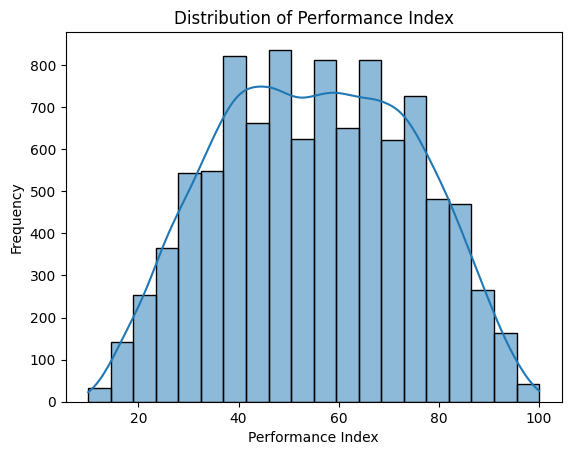

In [94]:
sns.histplot(df['Performance Index'], bins=20, kde=True)
plt.title('Distribution of Performance Index')
plt.xlabel('Performance Index')
plt.ylabel('Frequency')
plt.show()

Performance Index ranges from about 10 to 100. Most students score between 40 and 80, and the distribution is fairly symmetric with no extreme outliers. This is good for linear regression because the target is not heavily skewed.

In [95]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.010676,0.002131,0.015740,0.375332
Previous Scores,-0.010676,1.000000,0.007975,0.008719,0.915135
Sleep Hours,0.002131,0.007975,1.000000,0.004907,0.050352
Sample Question Papers Practiced,0.015740,0.008719,0.004907,1.000000,0.043436
Performance Index,0.375332,0.915135,0.050352,0.043436,1.000000


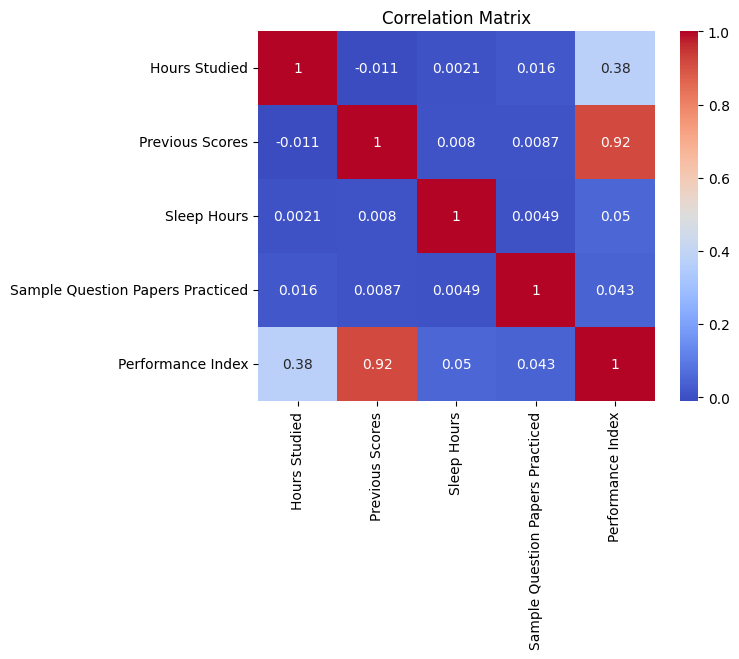

In [96]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Previous Scores has a very strong positive correlation with Performance Index (0.92). Hours Studied has a moderate correlation (0.38). Sleep Hours and Sample Question Papers Practiced have almost no correlation (around 0.05). The features are also not correlated with each other, so there is no multicollinearity problem.

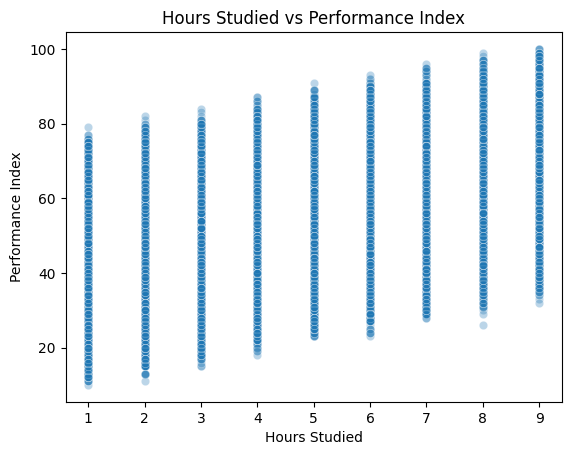

In [97]:
sns.scatterplot(x=df['Hours Studied'], y=df['Performance Index'], alpha=0.3)
plt.title('Hours Studied vs Performance Index')
plt.xlabel('Hours Studied')
plt.ylabel('Performance Index')
plt.show()

Performance Index tends to increase as Hours Studied increases, but the relationship is not very strong. For each number of hours, the scores are spread widely, which means Hours Studied alone cannot predict the score well. Other features, such as Previous Scores, must play a bigger role.

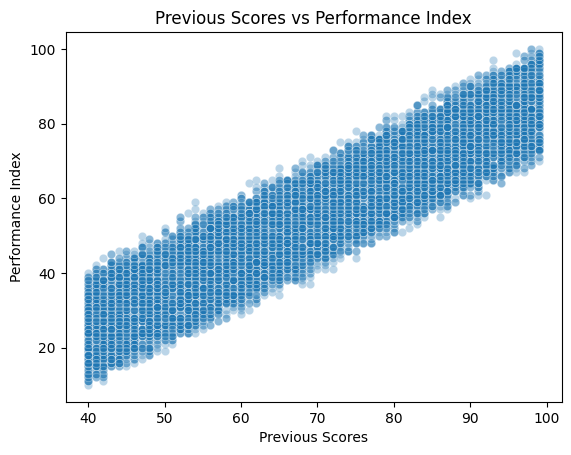

In [98]:
sns.scatterplot(x=df['Previous Scores'], y=df['Performance Index'], alpha=0.3)
plt.title('Previous Scores vs Performance Index')
plt.xlabel('Previous Scores')
plt.ylabel('Performance Index')
plt.show()

Previous Scores and Performance Index have a clear, almost straight-line relationship. Students with higher previous scores tend to have a higher Performance Index. The spread around the trend is fairly even, so a linear model should fit this data well.

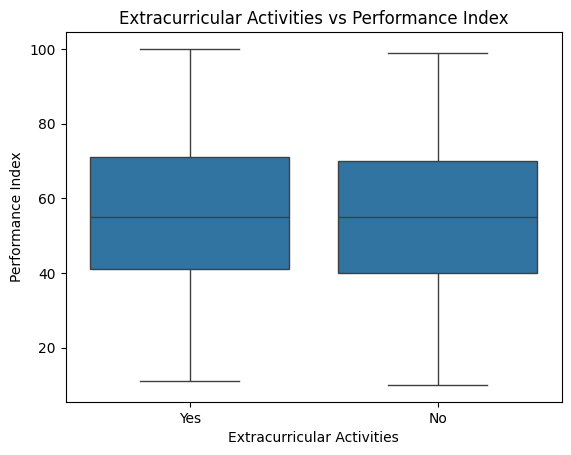

In [99]:
sns.boxplot(x=df['Extracurricular Activities'], y=df['Performance Index'])
plt.title('Extracurricular Activities vs Performance Index')
plt.xlabel('Extracurricular Activities')
plt.ylabel('Performance Index')
plt.show()

Students who do extracurricular activities and those who don't have almost the same median Performance Index (around 55). The spread is also very similar. So this feature seems to have little effect on the score.

## 6. Data Preparation

The Extracurricular Activities column was text (Yes/No), so I converted it to numbers: Yes = 1 and No = 0. The model can only work with numbers.

In [100]:
df['Extracurricular Activities'] = df['Extracurricular Activities'].map({'Yes': 1, 'No': 0})
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [101]:
df['Extracurricular Activities'].isnull().sum()

np.int64(0)

### Splitting Features and Target

I separated the data into features (X) and target (y). Then I split it into 80% training data and 20% testing data.

In [102]:
from sklearn.model_selection import train_test_split

x = df.drop(columns=['Performance Index'])
y = df['Performance Index']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [103]:
print(x_train.shape, x_test.shape)
print(y_train.shape, y_test.shape)

(7898, 5) (1975, 5)
(7898,) (1975,)


## 7. Building the Linear Regression Model

I will train a linear regression model on the training data and use it to predict the scores of the test data.

In [104]:
from sklearn.linear_model import LinearRegression

model= LinearRegression()

model.fit(x_train, y_train)

LinearRegression()

In [105]:
y_predict= model.predict(x_test)

In [106]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_predict)
mae = mean_absolute_error(y_test, y_predict)
rmse = np.sqrt(mean_squared_error(y_test, y_predict))

print("R2 Score:", r2)
print("MAE:", mae)
print("RMSE:", rmse)

R2 Score: 0.9884301209927054
MAE: 1.6469703984255573
RMSE: 2.0750664901488047


In [107]:
pd.DataFrame({'Feature': x.columns, 'Coefficient': model.coef_})

,Feature,Coefficient
0,Hours Studied,2.851022
1,Previous Scores,1.018430
2,Extracurricular Activities,0.573823
3,Sleep Hours,0.472073
4,Sample Question Papers Practiced,0.188704


The model works very well on unseen data. R² is 0.988, so it explains about 98.8% of the variation in Performance Index. On average, the predictions are off by only about 1.65 points (MAE).

## 8. Model Evaluation

### Actual vs Predicted

I will compare the actual Performance Index with the model's predictions to see how close they are.

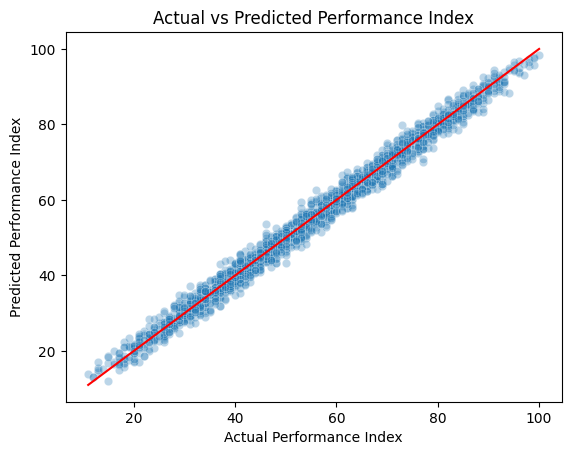

In [114]:
sns.scatterplot(x=y_test, y=y_predict, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Actual Performance Index')
plt.ylabel('Predicted Performance Index')
plt.title('Actual vs Predicted Performance Index')
plt.show()

The red line is the perfect prediction line (actual = predicted). Most points sit very close to this line, so the model predicts well. This matches the high R² score of 0.988.

### Residual Plot

A residual is the difference between the actual and predicted value (actual - predicted). I will plot the residuals to check if the model's errors are random.

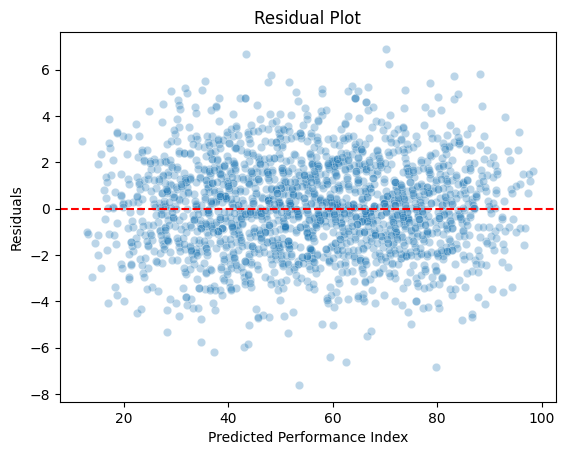

In [115]:
residuals = y_test - y_predict

sns.scatterplot(x=y_predict, y=residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Performance Index')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

The residuals are randomly scattered around 0 with no clear pattern, and the spread looks similar across all predicted values. This means the linear regression assumptions hold and the model fits well. Most errors fall between about -6 and +6 points, with only a few outliers.

## 9. Model Coefficients

Each coefficient shows how much the Performance Index changes when that feature goes up by 1, while all other features stay the same.

In [117]:
coef_df = pd.DataFrame({'Feature': x.columns, 'Coefficient': model.coef_})
coef_df

,Feature,Coefficient
0,Hours Studied,2.851022
1,Previous Scores,1.018430
2,Extracurricular Activities,0.573823
3,Sleep Hours,0.472073
4,Sample Question Papers Practiced,0.188704


In [118]:
model.intercept_

np.float64(-33.981324496440635)

The intercept is -33.98. This is the predicted Performance Index when all features are 0. It is only the starting point of the line and has no real-life meaning here.

- **Hours Studied (2.85):** If a student studies 1 more hour, and everything else stays the same, the Performance Index goes up by about 2.85 points.
- **Previous Scores (1.02):** If a student's previous score goes up by 1 point, and everything else stays the same, the Performance Index goes up by about 1.02 points.
- **Extracurricular Activities (0.57):** If a student does extracurricular activities (instead of not doing them), and everything else stays the same, the Performance Index goes up by about 0.57 points.
- **Sleep Hours (0.47):** If a student sleeps 1 more hour, and everything else stays the same, the Performance Index goes up by about 0.47 points.
- **Sample Question Papers Practiced (0.19):** If a student practices 1 more paper, and everything else stays the same, the Performance Index goes up by about 0.19 points.

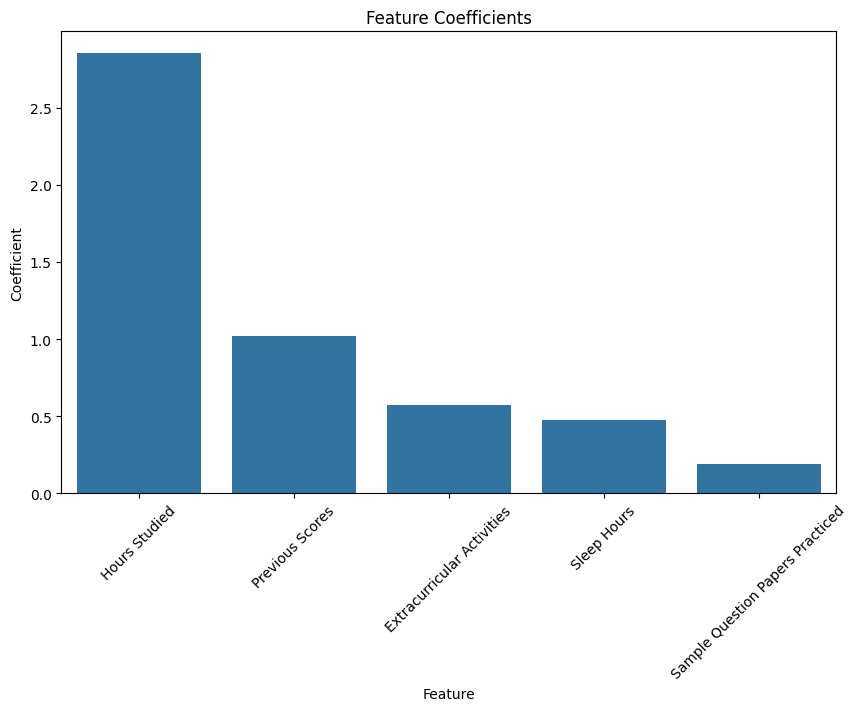

In [126]:
plt.figure(figsize=(10,6))

sns.barplot( x='Feature',y='Coefficient', data=coef_df)
plt.title('Feature Coefficients')
plt.xticks(rotation=45)
plt.show()

Hours Studied has the largest coefficient (2.85), followed by Previous Scores (1.02). Sleep Hours, Extracurricular Activities, and Sample Question Papers Practiced have small coefficients, so they change the score only a little.

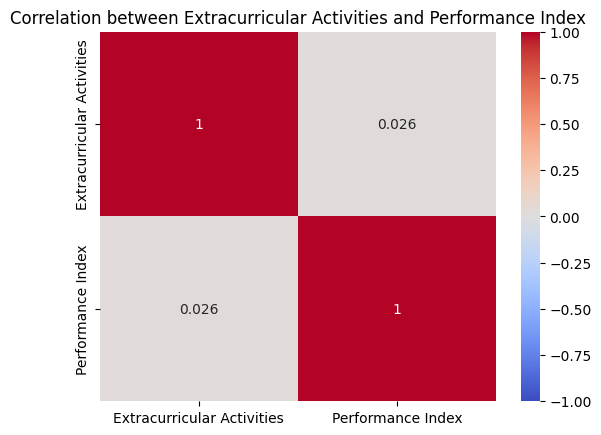

In [130]:
corr_subset = df[['Extracurricular Activities', 'Performance Index']].corr()
sns.heatmap(corr_subset, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between Extracurricular Activities and Performance Index')
plt.show()

After converting Extracurricular Activities to 0/1, its correlation with Performance Index is 0.026, which is very weak. This matches the boxplot, where both groups had almost the same median score.

## 10. Conclusion

In this project, I built a linear regression model to predict a student's Performance Index.

- The model works very well. R² is 0.988, so it explains about 98.8% of the variation in the score.
- On average, the predictions are off by only about 1.65 points (MAE).
- The residual plot shows no pattern, so the linear model fits this data well.
- Previous Scores has the strongest link with the Performance Index (correlation 0.92).
- Hours Studied also helps: 1 extra hour adds about 2.85 points.
- Sleep Hours and Sample Question Papers Practiced have only a small effect.
- Extracurricular Activities has almost no effect (correlation 0.026).

**Limitations:** The model only finds straight-line relationships, and this dataset is very clean. Real-world data would give less accurate results.